Here's the plan:
Phase 1 — Train 3 backbones independently

ResNet50, EfficientNet-B3, DenseNet121
Each trained with mixup + GPU augmentation + cosine LR scheduling

Phase 2 — Ensemble evaluation

Average softmax probabilities across all 3 models
This is the primary classifier

Phase 3 — Feature bank + FAISS

Extract concatenated features from all 3 backbones (2048 + 1536 + 1024 = 4608 dims)
L2 normalize and store in a FAISS index
k-NN over this bank gives a second prediction

Phase 4 — Few-shot extensibility

If a new disease class appears that wasn't in training, you can add it by just providing a few support images
Their features get extracted and added to the FAISS bank
No retraining needed — the k-NN handles it automatically via add_new_class()

Final prediction

Ensemble softmax for known classes (high confidence)
k-NN fallback for low confidence or novel classes
The two signals can be combined or compared

The key insight is FAISS handles new classes at zero cost, while the ensemble handles known classes with high accuracy.

# Imports

In [1]:
!pip install torch torchvision torch-summary pandas albumentations regex Pillow faiss-cpu pynvml GPUtil

import subprocess
import sys
import os
import glob
import json
import time
import copy
import numpy as np
import pandas as pd
import regex as re
from collections import defaultdict
from PIL import Image
from pathlib import Path

from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.transforms.v2 as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import GradScaler, autocast

from sklearn.model_selection import train_test_split
from tqdm import tqdm

import faiss
import pynvml
import GPUtil

import kagglehub
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

tushar5harma_path    = kagglehub.dataset_download('tushar5harma/plant-village-dataset-updated')
shubham2703_path     = kagglehub.dataset_download('shubham2703/five-crop-diseases-dataset')
zunorain_path        = kagglehub.dataset_download('zunorain/pea-plant-dataset')
mexwell_path         = kagglehub.dataset_download('mexwell/crop-diseases-classification')
ayushbpanchal_path   = kagglehub.dataset_download('ayushbpanchal/cashew-image-dataset')
tahmidmir_path       = kagglehub.dataset_download('tahmidmir/pumpkin-leaf-diseases-dataset-from-bangladesh')
binnassor89_path     = kagglehub.dataset_download('binnassor89/melon-macronutrient-deficiency-dataset')
nirmalsankalana_path = kagglehub.dataset_download('nirmalsankalana/rocole-a-robusta-coffee-leaf-images-dataset')
yasaminborhani_path = kagglehub.dataset_download('yasaminborhani/wheatrustclassificationdataset')

print('Downloads complete.')

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 85.9 MB/s eta 0:00:00:00:0100:01
  Created wheel for GPUtil: filename=GPUtil-1.4.0-py3-none-any.whl size=7392 sha256=fe4ee0330441129e12aad1cfe5dbe75e979be6f5d57de69bf399b4d512bb8d0a
  Stored in directory: /root/.cache/pip/wheels/92/a8/b7/d8a067c31a74de9ca252bbe53dea5f896faabd25d55f541037
Successfully built GPUtil
Downloads complete.


# Config

In [2]:
# Global Settings
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
print(f'Using device: {device}')

# Mixed precision scaler
scaler = GradScaler()

# Directories
kaggle_input = '/kaggle/input'
runs_dir     = '/kaggle/working/runs'
bank_prefix  = '/kaggle/working/runs/feature_bank'
os.makedirs(runs_dir, exist_ok=True)

base = '/kaggle/input/datasets'
image_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

batch_size = 64
num_workers = 4
seed = 42
n_epochs = 20 
img_size = 224
early_stop_patience = 4

lr_head   = 5e-4 
lr_top    = 5e-5
lr_mid    = 2e-5
lr_bottom = 1e-5

base_input = '/kaggle/input/datasets'

dataset_roots = {
    'shubham2703':     f'{base_input}/shubham2703',
    'nirmalsankalana': f'{base_input}/nirmalsankalana',
    'binnassor89':     f'{base_input}/binnassor89',
    'zunorain':        f'{base_input}/zunorain',
    'ayushbpanchal':   f'{base_input}/ayushbpanchal/cashew-image-dataset/Cashew',
    'tahmidmir':       f'{base_input}/tahmidmir',
    'yasaminborhani':  f'{base_input}/yasaminborhani',
    'mexwell':         f'{base_input}/mexwell/crop-diseases-classification/Data',
    'tushar5harma':    f'{base_input}/tushar5harma/plant-village-dataset-updated',
}

Using device: cuda


/tmp/ipykernel_57/2769695175.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


# Label Maps & Class Index

In [3]:
dataset_label_maps = {

    # tushar5harma: keyed by (crop_dir, disease_dir) — 3-level: Crop/Split/Disease
    "tushar5harma": {
        ("Apple",        "Apple Scab")             : "Apple__Apple_Scab",
        ("Apple",        "Black Rot")              : "Apple__Black_Rot",
        ("Apple",        "Cedar Apple Rust")       : "Apple__Cedar_Apple_Rust",
        ("Apple",        "Healthy")                : "Apple__Healthy",
        ("Bell Pepper",  "Bacterial Spot")         : "Bell_Pepper__Bacterial_Spot",
        ("Bell Pepper",  "Healthy")                : "Bell_Pepper__Healthy",
        ("Cherry",       "Healthy")                : "Cherry__Healthy",
        ("Cherry",       "Powdery Mildew")         : "Cherry__Powdery_Mildew",
        ("Corn (Maize)", "Cercospora Leaf Spot")   : "Corn__Gray_Leaf_Spot",
        ("Corn (Maize)", "Common Rust")            : "Corn__Common_Rust",
        ("Corn (Maize)", "Healthy")                : "Corn__Healthy",
        ("Corn (Maize)", "Northern Leaf Blight")   : "Corn__Northern_Leaf_Blight",
        ("Grape",        "Black Rot")              : "Grape__Black_Rot",
        ("Grape",        "Esca (Black Measles)")   : "Grape__Black_Measles",
        ("Grape",        "Healthy")                : "Grape__Healthy",
        ("Grape",        "Leaf Blight")            : "Grape__Leaf_Blight",
        ("Peach",        "Bacterial Spot")         : "Peach__Bacterial_Spot",
        ("Peach",        "Healthy")                : "Peach__Healthy",
        ("Potato",       "Early Blight")           : "Potato__Early_Blight",
        ("Potato",       "Healthy")                : "Potato__Healthy",
        ("Potato",       "Late Blight")            : "Potato__Late_Blight",
        ("Strawberry",   "Healthy")                : "Strawberry__Healthy",
        ("Strawberry",   "Leaf Scorch")            : "Strawberry__Leaf_Scorch",
        ("Tomato",       "Bacterial Spot")         : "Tomato__Bacterial_Spot",
        ("Tomato",       "Early Blight")           : "Tomato__Early_Blight",
        ("Tomato",       "Healthy")                : "Tomato__Healthy",
        ("Tomato",       "Late Blight")            : "Tomato__Late_Blight",
        ("Tomato",       "Septoria Leaf Spot")     : "Tomato__Septoria_Leaf_Spot",
        ("Tomato",       "Yellow Leaf Curl Virus") : "Tomato__Yellow_Leaf_Curl_Virus",
    },

    # shubham2703: structure is Crop Diseases/Crop___Disease/{Crop}/{Class}/*.jpg
    # rglob parent.name gives the leaf class folder name e.g. "Corn___Common_Rust"
    "shubham2703": {
        "Corn___Common_Rust"          : "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot"       : "Corn__Gray_Leaf_Spot",
        "Corn___Healthy"              : "Corn__Healthy",
        "Corn___Northern_Leaf_Blight" : "Corn__Northern_Leaf_Blight",
        "Potato___Early_Blight"       : "Potato__Early_Blight",
        "Potato___Healthy"            : "Potato__Healthy",
        "Potato___Late_Blight"        : "Potato__Late_Blight",
        "Rice___Brown_Spot"           : "Rice__Brown_Spot",
        "Rice___Healthy"              : "Rice__Healthy",
        "Rice___Leaf_Blast"           : "Rice__Leaf_Blast",
        "Rice___Neck_Blast"           : "Rice__Neck_Blast",
        "Wheat___Brown_Rust"          : "Wheat__Brown_Rust",
        "Wheat___Healthy"             : "Wheat__Healthy",
        "Wheat___Yellow_Rust"         : "Wheat__Yellow_Rust",
        "Bacterial Blight"            : "Rice__Bacterial_Blight",
        "Red Rot"                     : "Sugarcane__Red_Rot",
    },

    # nirmalsankalana: only coffee classes present on disk
    "nirmalsankalana": {
        "coffee___healthy"         : "Coffee__Healthy",
        "coffee___red_spider_mite" : "Coffee__Red_Spider_Mite",
        "coffee___rust"            : "Coffee__Rust",
        "BlackMeasles"             : "Grape__Black_Measles",
        "BlackRot"                 : "Grape__Black_Rot",
        "HealthyGrapes"            : "Grape__Healthy",
        "LeafBlight"               : "Grape__Leaf_Blight",
    },

    # binnassor89: actual folder names confirmed from disk
    "binnassor89": {
        "calcium"   : "Melon__Calcium_Deficiency",
        "health"    : "Melon__Healthy",
        "nitrogen"  : "Melon__Nitrogen_Deficiency",
        "potasium"  : "Melon__Potassium_Deficiency",   # sic — matches disk
    },

    # zunorain: actual folder names confirmed from disk
    "zunorain": {
        "DOWNY_MILDEW_LEAF"  : "Pea__Downy_Mildew",
        "FRESH_LEAF"         : "Pea__Healthy",
        "LEAFMINNER_LEAF"    : "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF" : "Pea__Powdery_Mildew",
    },

    # ayushbpanchal: train_set + test_set both present; rglob picks both
    "ayushbpanchal": {
        "anthracnose" : "Cashew__Anthracnose",
        "gumosis"     : "Cashew__Gummosis",
        "healthy"     : "Cashew__Healthy",
        "leaf miner"  : "Cashew__Leaf_Miner",
        "red rust"    : "Cashew__Red_Rust",
    },

    # tahmidmir: Original Dataset/{Class}/*.jpg — rglob parent.name = class folder
    "tahmidmir": {
        "Bacterial Leaf Spot" : "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew"        : "Pumpkin__Downy_Mildew",
        "Healthy Leaf"        : "Pumpkin__Healthy",
        "Mosaic Disease"      : "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew"      : "Pumpkin__Powdery_Mildew",
    },

    # mexwell: CSV-based — label resolved via label_num_to_disease_map.json
    "mexwell": {
        "Cassava Bacterial Blight (CBB)"      : "Cassava__Bacterial_Blight",
        "Cassava Brown Streak Disease (CBSD)" : "Cassava__Brown_Streak_Disease",
        "Cassava Green Mottle (CGM)"          : "Cassava__Green_Mottle",
        "Cassava Mosaic Disease (CMD)"        : "Cassava__Mosaic_Disease",
        "Healthy"                             : "Cassava__Healthy",
    },
    "yasaminborhani": {
        "Brown_rust"  : "Wheat__Brown_Rust",
        "Healthy"     : "Wheat__Healthy",
        "Yellow_rust" : "Wheat__Yellow_Rust",
    },
}

# Build global class_to_idx  (must match Phase B exactly — same label maps)
all_canonical = sorted(set(
    v for mapping in dataset_label_maps.values()
    for v in mapping.values()
    if v is not None
))
class_to_idx = {cls: idx for idx, cls in enumerate(all_canonical)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}
n_classes    = len(class_to_idx)
print(f"Total canonical classes: {n_classes}")

Total canonical classes: 64


# Sample Builders 

In [4]:
def build_samples_folder(slug: str) -> list:
    label_map = dataset_label_maps[slug]
    root = Path(base) / slug
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        raw_label = img_path.parent.name
        canonical = None
        
        # Special handling for bare 'Healthy' in shubham2703
        if slug == "shubham2703" and raw_label == "Healthy":
            # Try to get crop from grandparent
            crop_folder = img_path.parent.parent.name
            # Crop folder names are like 'Corn', 'Potato', 'Rice', 'Wheat', 'Sugarcane'
            # But the canonical class expects e.g., 'Corn__Healthy'
            if crop_folder in ["Corn", "Potato", "Rice", "Wheat", "Sugarcane"]:
                canonical = f"{crop_folder}__Healthy"
                # Ensure it exists in class_to_idx (it should)
                if canonical not in class_to_idx:
                    canonical = None
        
        if canonical is None:
            canonical = label_map.get(raw_label)
        
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{slug:<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_tushar() -> list:
    label_map = dataset_label_maps["tushar5harma"]
    root = Path(base) / "tushar5harma"
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        disease_dir = img_path.parent
        split_dir = disease_dir.parent
        crop_dir = split_dir.parent
        
        # Skip checkpoint folders
        if disease_dir.name.startswith('.') or split_dir.name.startswith('.'):
            skipped += 1
            continue
        
        # Strip trailing/leading spaces from disease name
        disease_name = disease_dir.name.strip()
        crop_name = crop_dir.name
        
        key = (crop_name, disease_name)
        canonical = label_map.get(key)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'tushar5harma':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_mexwell() -> list:
    """
    CSV-based. Label resolved via label_num_to_disease_map.json (int key → disease name).
    """
    data_root = Path(base) / "mexwell" / "crop-diseases-classification" / "Data"
    img_dir   = data_root / "train_images"
    json_path = data_root / "label_num_to_disease_map.json"
    csv_path  = data_root / "train.csv"

    with open(json_path) as f:
        num_to_name = json.load(f)   # {"0": "Cassava Bacterial Blight (CBB)", ...}

    df        = pd.read_csv(csv_path)
    label_map = dataset_label_maps["mexwell"]
    samples, skipped = [], 0

    for _, row in df.iterrows():
        img_path     = img_dir / row["image_id"]
        if not img_path.exists():
            skipped += 1
            continue
        disease_name = num_to_name[str(row["label"])]
        canonical    = label_map.get(disease_name)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))

    print(f"  [{'mexwell':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_all_samples():
    print("Loading datasets...")
    folder_slugs = ["shubham2703", "nirmalsankalana", "binnassor89",
                    "zunorain", "ayushbpanchal", "tahmidmir", "yasaminborhani"]
    all_samples = []
    for slug in folder_slugs:
        all_samples += build_samples_folder(slug)
    all_samples += build_samples_mexwell()
    all_samples += build_samples_tushar()
    print(f"\nTotal: {len(all_samples):,} samples | "
          f"{len(set(lbl for _, lbl in all_samples))} unique class indices")
    return all_samples

# Transforms

In [5]:
# Use torchvision transforms (compatible, no version issues)
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Dataset Builder

In [6]:
class CropDiseaseDataset(Dataset):
    """samples: list of (path_str, class_idx_int) — same format as Phase B."""
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

# DataLoaders

In [7]:
def build_dataloaders(all_samples):
    labels = [lbl for _, lbl in all_samples]
    train_s, val_s = train_test_split(
        all_samples, test_size=0.15, random_state=seed, stratify=labels
    )
    train_ds = CropDiseaseDataset(train_s, transform=train_transform)
    val_ds   = CropDiseaseDataset(val_s,   transform=val_transform)

    train_labels = [lbl for _, lbl in train_s]
    class_counts = np.bincount(train_labels, minlength=n_classes)
    class_weights = 1.0 / (class_counts + 1e-6)
    sample_w = [class_weights[l] for l in train_labels]
    sampler = WeightedRandomSampler(sample_w, num_samples=len(sample_w), replacement=True)

    kw = dict(num_workers=num_workers, prefetch_factor=4,
              persistent_workers=True, pin_memory=True)
    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler, **kw)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,   **kw)
    print(f'Train: {len(train_ds):,}  |  Val: {len(val_ds):,}')
    return train_loader, val_loader, train_s, val_s

# Backbone

In [8]:
class ResNet50Backbone(nn.Module):
    feature_dim = 2048

    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        self.encoder = nn.Sequential(*list(base.children())[:-1])
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.feature_dim, n_classes)
        )

    def extract_features(self, x):
        return self.encoder(x).flatten(1)

    def forward(self, x):
        return self.head(self.extract_features(x))

class EfficientNetB3Backbone(nn.Module):
    feature_dim = 1536

    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        base = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        self.encoder = base.features
        self.pool = base.avgpool
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.feature_dim, n_classes)
        )

    def extract_features(self, x):
        # No in-place ops
        x = self.encoder(x)
        x = self.pool(x)
        return x.flatten(1)

    def forward(self, x):
        return self.head(self.extract_features(x))

class DenseNet121Backbone(nn.Module):
    feature_dim = 1024

    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.encoder = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.feature_dim, n_classes)
        )

    def extract_features(self, x):
        x = self.encoder(x)
        x = F.relu(x)  # no inplace
        x = self.pool(x)
        return x.flatten(1)

    def forward(self, x):
        return self.head(self.extract_features(x))

backbone_names = ['resnet50', 'efficientnet', 'densenet']

def build_all_backbones(n_classes):
    backbones = {
        'resnet50': ResNet50Backbone(n_classes).to(device),
        'efficientnet': EfficientNetB3Backbone(n_classes).to(device),
        'densenet': DenseNet121Backbone(n_classes).to(device),
    }
    for name, m in backbones.items():
        n_params = sum(p.numel() for p in m.parameters()) / 1e6
        print(f'  {name:<15} {n_params:.1f}M params')
    return backbones

# Optimizers

In [9]:
def build_optimizer_resnet(model):
    base = model  # no DataParallel
    enc = list(base.encoder.children())
    return optim.AdamW([
        {'params': list(enc[0].parameters()) + list(enc[1].parameters()), 'lr': lr_bottom},
        {'params': enc[4].parameters(), 'lr': lr_bottom},
        {'params': enc[5].parameters(), 'lr': lr_mid},
        {'params': enc[6].parameters(), 'lr': lr_top},
        {'params': enc[7].parameters(), 'lr': lr_top},
        {'params': base.head.parameters(), 'lr': lr_head},
    ], weight_decay=1e-4)

def build_optimizer_efficientnet(model):
    base = model
    enc = list(base.encoder.children())
    n = len(enc)
    mid_idx = n // 2
    return optim.AdamW([
        {'params': enc[0].parameters(), 'lr': lr_bottom},
        {'params': sum([list(enc[i].parameters()) for i in range(1, mid_idx)], []), 'lr': lr_mid},
        {'params': sum([list(enc[i].parameters()) for i in range(mid_idx, n)], []), 'lr': lr_top},
        {'params': base.head.parameters(), 'lr': lr_head},
    ], weight_decay=1e-4)

def build_optimizer_densenet(model):
    base = model
    enc = list(base.encoder.children())
    n = len(enc)
    mid_idx = n // 2
    return optim.AdamW([
        {'params': enc[0].parameters(), 'lr': lr_bottom},
        {'params': sum([list(enc[i].parameters()) for i in range(1, mid_idx)], []), 'lr': lr_mid},
        {'params': sum([list(enc[i].parameters()) for i in range(mid_idx, n)], []), 'lr': lr_top},
        {'params': base.head.parameters(), 'lr': lr_head},
    ], weight_decay=1e-4)

def build_optimizers(backbones):
    return {
        'resnet50': build_optimizer_resnet(backbones['resnet50']),
        'efficientnet': build_optimizer_efficientnet(backbones['efficientnet']),
        'densenet': build_optimizer_densenet(backbones['densenet']),
    }

# Training Utilities

In [10]:
class AverageMeter:
    def __init__(self):
        self.reset()
    def reset(self):
        self.sum = 0
        self.count = 0
        self.avg = 0
    def update(self, val, n=1):
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

def accuracy_topk(output, target, topk=(1, 5)):
    with torch.no_grad():
        maxk = max(topk)
        bs = target.size(0)
        _, pred = output.topk(maxk, dim=1, largest=True, sorted=True)
        correct = pred.t().eq(target.view(1, -1).expand_as(pred.t()))
        return [correct[:k].reshape(-1).float().sum().mul_(100.0 / bs).item() for k in topk]

def mixup_data(x, y, alpha=0.4):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    return mixed_x, y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def train_one_epoch(name, model, loader, criterion, optimizer, epoch, use_mixup=True):
    model.train()
    loss_meter = AverageMeter()
    top1_meter = AverageMeter()
    top5_meter = AverageMeter()
    loop = tqdm(loader, desc=f'{name} E{epoch}')
    for imgs, labels in loop:
        imgs, labels = imgs.to(device), labels.to(device)
        if use_mixup:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels)
        else:
            y_a, y_b, lam = labels, labels, 1.0

        optimizer.zero_grad()
        out = model(imgs)
        loss = mixup_criterion(criterion, out, y_a, y_b, lam)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        top1, top5 = accuracy_topk(out, y_a)
        loss_meter.update(loss.item(), imgs.size(0))
        top1_meter.update(top1, imgs.size(0))
        top5_meter.update(top5, imgs.size(0))

        loop.set_postfix(loss=loss_meter.avg, acc1=top1_meter.avg)
    return loss_meter.avg, top1_meter.avg, top5_meter.avg

@torch.no_grad()
def evaluate(name, model, loader):
    model.eval()
    t1 = t5 = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        a1, a5 = accuracy_topk(out, labels)
        bs = labels.size(0)
        t1 += a1 * bs
        t5 += a5 * bs
        total += bs
    top1 = t1 / total
    top5 = t5 / total
    print(f'  [{name}] Val top1={top1:.2f}%  top5={top5:.2f}%')
    return top1, top5

# Checkpoint Save / Load

In [11]:
def save_checkpoint(name, model, optimizer, scheduler, epoch, val_top1, tag, history=None):
    path = os.path.join(runs_dir, f'{name}_{tag}.pth')
    torch.save({
        'backbone': name,
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'best_acc': val_top1,
        'class_to_idx': class_to_idx,
        'n_classes': n_classes,
        'history': history or [],
    }, path)
    print(f'  → {name}_{tag}.pth  (top1={val_top1:.4f})')
    return path

def load_checkpoint(name, model, path):
    ckpt = torch.load(path, map_location='cpu')
    model.load_state_dict(ckpt['model_state_dict'])
    print(f'  Loaded {name} | epoch={ckpt["epoch"]} | best_acc={ckpt["best_acc"]:.4f}')
    return ckpt

# Training Loop

In [12]:
def train_backbone(name, model, train_loader, val_loader, optimizer, n_epochs=n_epochs):
    resume_path = os.path.join(runs_dir, f'{name}_latest.pth')
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min=1e-7)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    start_epoch = 0
    best_top1 = 0.0
    no_improve = 0
    history = []

    if os.path.exists(resume_path):
        print(f'\nResuming {name} from {resume_path}')
        ckpt = torch.load(resume_path, map_location='cpu')
        model.load_state_dict(ckpt['model_state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])
        start_epoch = ckpt['epoch'] + 1
        best_top1 = ckpt.get('best_acc', 0.0)
        history = ckpt.get('history', [])
        print(f'  Resumed at epoch {start_epoch}, best_top1={best_top1:.4f}')

    print(f'\n{"="*60}')
    print(f'Training: {name}  |  epochs {start_epoch}..{n_epochs-1}')
    print(f'{"="*60}')

    for epoch in range(start_epoch, n_epochs):
        tr_loss, tr1, tr5 = train_one_epoch(name, model, train_loader, criterion, optimizer, epoch)
        val_top1, val_top5 = evaluate(name, model, val_loader)
        scheduler.step()

        history.append(dict(epoch=epoch, tr_loss=tr_loss, tr_top1=tr1,
                            val_top1=val_top1, val_top5=val_top5))
        print(f'  Epoch {epoch}: train_top1={tr1:.2f}%  val_top1={val_top1:.2f}%')

        save_checkpoint(name, model, optimizer, scheduler, epoch, val_top1, 'latest', history)

        if val_top1 > best_top1:
            best_top1 = val_top1
            no_improve = 0
            save_checkpoint(name, model, optimizer, scheduler, epoch, val_top1, 'best', history)
        else:
            no_improve += 1
            print(f'  No improvement ({no_improve}/{early_stop_patience})')
            if no_improve >= early_stop_patience:
                print(f'  Early stopping {name} at epoch {epoch}')
                break

    print(f'\n{name} done. Best val top1: {best_top1:.4f}')
    return os.path.join(runs_dir, f'{name}_best.pth')

In [13]:
all_samples = build_all_samples()
train_loader, val_loader, train_s, val_s = build_dataloaders(all_samples)

Loading datasets...
  [shubham2703         ]  13224 samples  (100 skipped)
  [nirmalsankalana     ]   1560 samples  (0 skipped)
  [binnassor89         ]    200 samples  (0 skipped)
  [zunorain            ]   1432 samples  (0 skipped)
  [ayushbpanchal       ]  25811 samples  (0 skipped)
  [tahmidmir           ]   2000 samples  (0 skipped)
  [yasaminborhani      ]   3679 samples  (0 skipped)
  [mexwell             ]  17938 samples  (3459 skipped)
  [tushar5harma        ]  67111 samples  (7 skipped)

Total: 132,955 samples | 64 unique class indices
Train: 113,011  |  Val: 19,944


In [14]:
# backbones = build_all_backbones(n_classes)
# optimizers = build_optimizers(backbones)

In [15]:
best_ckpt_paths = {}

for name in backbone_names:
    # Build model
    cls_map = {
        'resnet50': ResNet50Backbone,
        'efficientnet': EfficientNetB3Backbone,
        'densenet': DenseNet121Backbone,
    }
    model = cls_map[name](n_classes).to(device)
    optimizer = {
        'resnet50': build_optimizer_resnet,
        'efficientnet': build_optimizer_efficientnet,
        'densenet': build_optimizer_densenet,
    }[name](model)
    
    # Train
    best_ckpt_paths[name] = train_backbone(
        name, model, train_loader, val_loader, optimizer, n_epochs=n_epochs
    )
    
    # Aggressively free GPU memory
    del model, optimizer
    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    
    print(f"GPU memory after {name}: {torch.cuda.memory_allocated()/1e9:.2f} GB")

print('\nAll backbones trained.')
print(best_ckpt_paths)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 186MB/s]



Resuming resnet50 from /kaggle/working/runs/resnet50_latest.pth
  Resumed at epoch 20, best_top1=95.3520

Training: resnet50  |  epochs 20..19

resnet50 done. Best val top1: 95.3520
GPU memory after resnet50: 0.00 GB
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 190MB/s]



Resuming efficientnet from /kaggle/working/runs/efficientnet_latest.pth
  Resumed at epoch 20, best_top1=86.9986

Training: efficientnet  |  epochs 20..19

efficientnet done. Best val top1: 86.9986
GPU memory after efficientnet: 0.00 GB
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s] 



Resuming densenet from /kaggle/working/runs/densenet_latest.pth
  Resumed at epoch 14, best_top1=94.9057

Training: densenet  |  epochs 14..19


densenet E14:   1%|          | 16/1766 [00:27<50:41,  1.74s/it, acc1=42.8, loss=1.28] 


KeyboardInterrupt: 

In [17]:
backbones = {} 
  
for name in backbone_names:
    best_path = os.path.join(runs_dir, f'{name}_best.pth')
    if not os.path.exists(best_path):
        raise FileNotFoundError(f"Missing checkpoint: {best_path}")
    
    cls_map = {
        'resnet50': ResNet50Backbone,
        'efficientnet': EfficientNetB3Backbone,
        'densenet': DenseNet121Backbone,
    }
    model = cls_map[name](n_classes).to(device)
    ckpt = torch.load(best_path, map_location='cpu')
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    backbones[name] = model
    print(f"Loaded {name} (best_acc={ckpt['best_acc']:.2f}%)")

print("All backbones ready for ensemble.")

Loaded resnet50 (best_acc=95.47%)
Loaded efficientnet (best_acc=87.14%)
Loaded densenet (best_acc=95.38%)
All backbones ready for ensemble.


# Ensemble Evaluation

In [18]:
def ensemble_predict(models, x):
    """Return averaged softmax probabiities over all models."""
    probs = []
    for model in models.values():
        with torch.no_grad(), autocast():
            logits = model(x)
            probs.append(F.softmax(logits, dim=1))
    return torch.stack(probs).mean(dim=0)

def ensemble_accuracy(models, val_loader):
    total = correct = 0
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        pred_probs = ensemble_predict(models, imgs)
        pred = pred_probs.argmax(dim=1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)
    acc = 100 * correct / total
    print(f'Ensemble Top-1 Accuracy: {acc:.2f}% ({correct}/{total})')
    return acc

ensemble_acc = ensemble_accuracy(backbones, val_loader)

/tmp/ipykernel_57/316264786.py:5: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), autocast():


Ensemble Top-1 Accuracy: 96.07% (19160/19944)


# Feature Extraction & FAISS

In [19]:
def extract_all_features(models, dataloader, device):
    """Extract concatenated L2-normalized features from all models."""
    for model in models.values():
        model.eval()
    features = []
    labels = []
    with torch.no_grad():
        for imgs, lbls in tqdm(dataloader, desc="Extracting features"):
            imgs = imgs.to(device)
            parts = []
            for model in models.values():
                with autocast():
                    feat = model.extract_features(imgs)
                parts.append(feat)
            concat = F.normalize(torch.cat(parts, dim=1), p=2, dim=1)
            features.append(concat.cpu().numpy())
            labels.append(lbls.cpu().numpy())
    features = np.vstack(features)
    labels = np.concatenate(labels)
    return features, labels

def build_faiss_index(features):
    index = faiss.IndexFlatIP(features.shape[1])
    index.add(features)
    return index

train_dataset_for_bank = CropDiseaseDataset(train_s, transform=val_transform)
train_loader_for_bank = DataLoader(train_dataset_for_bank, batch_size=256, shuffle=False, num_workers=num_workers, pin_memory=True)
print("Extracting features for reference bank...")
bank_features, bank_labels = extract_all_features(backbones, train_loader_for_bank, device)
print(f"Extracted shape: {bank_features.shape}")

print("Building FAISS index...")
faiss_index = build_faiss_index(bank_features)
print("Index built.")

# Save for later use
os.makedirs(bank_prefix, exist_ok=True)
np.save(f'{bank_prefix}_features.npy', bank_features)
np.save(f'{bank_prefix}_labels.npy', bank_labels)

Extracting features for reference bank...


Extracting features:   0%|          | 0/442 [00:00<?, ?it/s]/tmp/ipykernel_57/1330686727.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Extracting features: 100%|██████████| 442/442 [08:51<00:00,  1.20s/it]


Extracted shape: (113011, 4608)
Building FAISS index...
Index built.


In [20]:
import numpy as np

feats  = np.load('/kaggle/working/runs/feature_bank_features.npy')
labels = np.load('/kaggle/working/runs/feature_bank_labels.npy')

print(f"Features shape: {feats.shape}")   # expect (113011, 4608)
print(f"Labels shape:   {labels.shape}")  # expect (113011,)
print(f"Label range:    {labels.min()} – {labels.max()}")  # expect 0 – 63
print(f"Unique classes: {len(set(labels.tolist()))}")       # expect 64

Features shape: (113011, 4608)
Labels shape:   (113011,)
Label range:    0 – 63
Unique classes: 64


# CropQuery Predictor

In [22]:
class CropQueryPredictor:
    def __init__(self, models_dict, features, labels, index,
                 class_to_idx, idx_to_class, k=7):
        self.models = models_dict
        self.features = features
        self.labels = labels
        self.index = index
        self.class_to_idx = dict(class_to_idx)
        self.idx_to_class = dict(idx_to_class)
        self.k = k
        self._next_idx = max(idx_to_class.keys()) + 1

    def _get_features(self, image_paths):
        feats = []
        for path in image_paths:
            img = val_transform(Image.open(path).convert('RGB')).unsqueeze(0).to(device)
            with torch.no_grad(), autocast():
                parts = [m.extract_features(img) for m in self.models.values()]
            concat = F.normalize(torch.cat(parts, dim=1), p=2, dim=1)
            feats.append(concat.cpu().numpy())
        return np.vstack(feats).astype(np.float32)

    def predict_ensemble(self, image_path):
        img = val_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
        probs = ensemble_predict(self.models, img)[0]
        idx = probs.argmax().item()
        return self.idx_to_class[idx], probs[idx].item()

    def predict_knn(self, image_path):
        feat = self._get_features([image_path])
        _, I = self.index.search(feat, self.k)
        nb_labels = self.labels[I[0]]
        counts = np.bincount(nb_labels, minlength=len(self.idx_to_class))
        best_idx = counts.argmax()
        return self.idx_to_class[best_idx], counts[best_idx] / self.k

    def add_new_class(self, class_name, support_image_paths):
        if class_name in self.class_to_idx:
            new_idx = self.class_to_idx[class_name]
            print(f'{class_name} exists — appending support images.')
        else:
            new_idx = self._next_idx
            self.class_to_idx[class_name] = new_idx
            self.idx_to_class[new_idx] = class_name
            self._next_idx += 1
            print(f'New class: {class_name} → idx {new_idx}')

        new_feats = self._get_features(support_image_paths)
        new_labels = np.full(len(support_image_paths), new_idx, dtype=np.int64)
        self.features = np.vstack([self.features, new_feats])
        self.labels = np.concatenate([self.labels, new_labels])
        self.index.add(new_feats)
        print(f'  Bank size: {self.index.ntotal:,}')
        return new_idx

    def save_updated_bank(self, prefix):
        np.save(f'{prefix}_features.npy', self.features)
        np.save(f'{prefix}_labels.npy', self.labels)
        # Optionally save index
        # faiss.write_index(faiss.index_gpu_to_cpu(self.index), f'{prefix}_index.bin')
        with open(f'{prefix}_class_map.json', 'w') as f:
            json.dump({'class_to_idx': self.class_to_idx,
                       'idx_to_class': {str(k): v for k, v in self.idx_to_class.items()}}, f, indent=2)

predictor = CropQueryPredictor(
    models_dict=backbones,
    features=bank_features,
    labels=bank_labels,
    index=faiss_index,
    class_to_idx=class_to_idx,
    idx_to_class=idx_to_class,
    k=7,
)
print('Predictor ready.')

Predictor ready.


# k-NN Accuracy on Val Set

In [23]:
@torch.no_grad()
def knn_accuracy_on_val(predictor, val_samples, batch_size=256):
    ds = CropDiseaseDataset(val_samples, transform=val_transform)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=True)
    correct = total = 0
    for imgs, labels in tqdm(loader, desc="k-NN eval"):
        imgs = imgs.to(device)
        parts = [m.extract_features(imgs) for m in predictor.models.values()]
        feats = F.normalize(torch.cat(parts, dim=1), p=2, dim=1).cpu().numpy()
        _, I = predictor.index.search(feats, predictor.k)
        for neighs, true_lbl in zip(I, labels.numpy()):
            pred = np.bincount(predictor.labels[neighs]).argmax()
            correct += int(pred == true_lbl)
            total += 1
    acc = 100 * correct / total
    print(f'k-NN (k={predictor.k}) Val Accuracy: {acc:.2f}%  ({correct}/{total})')
    return acc

knn_acc = knn_accuracy_on_val(predictor, val_s)

k-NN eval: 100%|██████████| 78/78 [06:02<00:00,  4.65s/it]

k-NN (k=7) Val Accuracy: 96.93%  (19331/19944)


# Verification Audits

In [24]:
# Checkpoint Shape

import torch

ckpts = {
    "resnet50":     "/kaggle/working/runs/resnet50_best.pth",
    "efficientnet": "/kaggle/working/runs/efficientnet_best.pth",
    "densenet":     "/kaggle/working/runs/densenet_best.pth",
}
for name, path in ckpts.items():
    ckpt = torch.load(path, map_location="cpu")
    keys = list(ckpt.keys())
    # find the classifier weight
    w = None
    for k in keys:
        if "weight" in k and "head" in k:
            w = ckpt[k]
            break
    if w is not None:
        print(f"{name}: {w.shape[0]} classes  (key: {k})")
    else:
        print(f"{name}: couldn't find head weight. Keys: {keys[:8]}")

resnet50: couldn't find head weight. Keys: ['backbone', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_acc', 'class_to_idx', 'n_classes']
efficientnet: couldn't find head weight. Keys: ['backbone', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_acc', 'class_to_idx', 'n_classes']
densenet: couldn't find head weight. Keys: ['backbone', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_acc', 'class_to_idx', 'n_classes']


In [25]:
for name, path in ckpts.items():
    ckpt = torch.load(path, map_location="cpu")
    print(f"{name}: {ckpt['n_classes']} classes, best_acc: {ckpt['best_acc']:.2f}%")

resnet50: 64 classes, best_acc: 95.47%
efficientnet: 64 classes, best_acc: 87.14%
densenet: 64 classes, best_acc: 95.38%


In [26]:
from collections import Counter

# Which classes have the most cross-split duplicates?
dup_classes = []
path_to_label = {p: l for p, l in train_s + val_s}
for train_p, val_p in collisions:
    label = path_to_label.get(val_p)
    if label is not None:
        dup_classes.append(idx_to_class[label])

dup_counts = Counter(dup_classes)
print(f"Duplicates by class (top 15):")
for cls, count in dup_counts.most_common(15):
    print(f"  {cls:<45} {count}")

NameError: name 'collisions' is not defined

In [ ]:
# per-class split counts

from collections import Counter

train_counts = Counter(lbl for _, lbl in train_s)
val_counts   = Counter(lbl for _, lbl in val_s)

print(f"{'Class':<45} {'Train':>6} {'Val':>5}")
print("-" * 58)
for idx in sorted(train_counts):
    cls = idx_to_class[idx]
    print(f"{cls:<45} {train_counts[idx]:>6} {val_counts.get(idx, 0):>5}")

print(f"\nTotal — Train: {len(train_s):,}  |  Val: {len(val_s):,}")

In [ ]:
# Duplicate image check 
import hashlib

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_paths = [p for p, _ in train_s]
val_paths   = [p for p, _ in val_s]

print("Hashing val images...")
val_hashes = {}
for p in val_paths:
    val_hashes[file_hash(p)] = p

print("Checking train images against val hashes...")
collisions = []
for p in train_paths:
    h = file_hash(p)
    if h in val_hashes:
        collisions.append((p, val_hashes[h]))

print(f"\nIdentical images across train/val: {len(collisions)}")
if collisions:
    for a, b in collisions[:5]:
        print(f"  TRAIN: {a}\n  VAL:   {b}\n")

# Evaluation

In [27]:
# ============================================================
# FULL EVALUATION — Test acc, per-class F1, confusion matrix
# Handles: duplicate-aware split + ablation in next cell
# ============================================================
import hashlib, numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from collections import defaultdict
from tqdm import tqdm

# ── Step 1: Build duplicate-aware held-out test split ────────
# Hash all samples, group by hash — duplicates must land in same split
print("Building duplicate-aware test split...")

hash_to_indices = defaultdict(list)
for i, (path, lbl) in enumerate(all_samples):
    try:
        with open(path, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()
        hash_to_indices[h].append(i)
    except:
        hash_to_indices[f"missing_{i}"].append(i)

# Treat each duplicate group as one unit — pick one representative index
unique_groups = list(hash_to_indices.values())
rep_indices   = [g[0] for g in unique_groups]
rep_labels    = [all_samples[i][1] for i in rep_indices]

# Stratified split on representative indices (15% test)
from sklearn.model_selection import train_test_split
rep_train, rep_test = train_test_split(
    rep_indices, test_size=0.15, random_state=seed, stratify=rep_labels
)

# Expand: test = all duplicates of test representatives
test_idx_set = set()
test_rep_set = set(rep_test)
for h, group in hash_to_indices.items():
    if group[0] in test_rep_set:
        test_idx_set.update(group)

test_s_clean = [all_samples[i] for i in test_idx_set]
# train+val = everything not in test
trainval_s   = [s for i, s in enumerate(all_samples) if i not in test_idx_set]

print(f"Clean test set : {len(test_s_clean):,} samples")
print(f"Train+val      : {len(trainval_s):,} samples")
print(f"Duplicate groups removed from test contamination: "
      f"{sum(1 for g in unique_groups if len(g)>1 and g[0] in test_rep_set)}")

# ── Step 2: DataLoader for clean test set ────────────────────
test_ds     = CropDiseaseDataset(test_s_clean, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False,
                         num_workers=num_workers, pin_memory=True)

# ── Step 3: Collect logits from each backbone ────────────────
@torch.no_grad()
def get_logits_and_labels(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for imgs, labels in tqdm(loader, desc="  Inferring", leave=False):
        imgs = imgs.to(device)
        with torch.amp.autocast('cuda'):
            logits = model(imgs)
        all_logits.append(logits.cpu())
        all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)

logits_per_backbone = {}
for name, model in backbones.items():
    print(f"\nRunning {name}...")
    logits, true_t = get_logits_and_labels(model, test_loader)
    logits_per_backbone[name] = logits

true_labels = true_t.numpy()

# ── Step 4: Per-backbone accuracy ────────────────────────────
print("\n" + "="*55)
print("  PER-BACKBONE TEST ACCURACY (duplicate-clean split)")
print("="*55)
backbone_results = {}
for name, logits in logits_per_backbone.items():
    preds = logits.argmax(dim=1).numpy()
    top1  = (preds == true_labels).mean() * 100
    top5  = np.mean([true_labels[i] in logits[i].topk(5).indices.numpy()
                     for i in range(len(true_labels))]) * 100
    backbone_results[name] = dict(top1=top1, top5=top5, preds=preds)
    print(f"  {name:<15}  Top-1: {top1:.2f}%   Top-5: {top5:.2f}%")

# ── Step 5: Ensemble accuracy ────────────────────────────────
print("\n" + "="*55)
print("  ENSEMBLE TEST ACCURACY")
print("="*55)
ensemble_logits = torch.stack(list(logits_per_backbone.values())).mean(dim=0)
ensemble_preds  = ensemble_logits.argmax(dim=1).numpy()
top1_ens = (ensemble_preds == true_labels).mean() * 100
top5_ens = np.mean([true_labels[i] in ensemble_logits[i].topk(5).indices.numpy()
                    for i in range(len(true_labels))]) * 100
print(f"  Ensemble        Top-1: {top1_ens:.2f}%   Top-5: {top5_ens:.2f}%")

# ── Step 6: Per-class report (ensemble) ──────────────────────
idx_to_class = {v: k for k, v in class_to_idx.items()}
class_names  = [idx_to_class[i] for i in range(n_classes)]

print("\n" + "="*55)
print("  CLASSIFICATION REPORT — Ensemble (test split)")
print("="*55)
report_str = classification_report(
    true_labels, ensemble_preds,
    target_names=class_names, digits=3, zero_division=0
)
print(report_str)

# Save report to file
with open('/kaggle/working/runs/classification_report.txt', 'w') as f:
    f.write(f"Ensemble Top-1: {top1_ens:.2f}%  Top-5: {top5_ens:.2f}%\n\n")
    f.write(report_str)

# ── Step 7: Confusion matrix ─────────────────────────────────
cm = confusion_matrix(true_labels, ensemble_preds)
np.save('/kaggle/working/runs/confusion_matrix.npy',   cm)
np.save('/kaggle/working/runs/test_true_labels.npy',   true_labels)
np.save('/kaggle/working/runs/test_pred_labels.npy',   ensemble_preds)

print(f"\nFiles saved to /kaggle/working/runs/")
print(f"  confusion_matrix.npy")
print(f"  classification_report.txt")
print(f"  test_true/pred_labels.npy")

Building duplicate-aware test split...
Clean test set : 19,984 samples
Train+val      : 112,971 samples
Duplicate groups removed from test contamination: 1660

Running resnet50...



Running efficientnet...



Running densenet...



  PER-BACKBONE TEST ACCURACY (duplicate-clean split)
  resnet50         Top-1: 96.52%   Top-5: 99.92%
  efficientnet     Top-1: 87.69%   Top-5: 95.49%
  densenet         Top-1: 96.04%   Top-5: 99.87%

  ENSEMBLE TEST ACCURACY
  Ensemble        Top-1: 96.92%   Top-5: 99.94%

  CLASSIFICATION REPORT — Ensemble (test split)
                                precision    recall  f1-score   support

             Apple__Apple_Scab      1.000     0.997     0.999       378
              Apple__Black_Rot      1.000     1.000     1.000       373
       Apple__Cedar_Apple_Rust      1.000     0.997     0.998       330
                Apple__Healthy      0.997     1.000     0.999       376
   Bell_Pepper__Bacterial_Spot      0.997     0.994     0.996       359
          Bell_Pepper__Healthy      0.992     1.000     0.996       373
           Cashew__Anthracnose      0.963     0.942     0.952       739
              Cashew__Gummosis      1.000     1.000     1.000       321
               Cashew__Heal

# Confusion Matrix

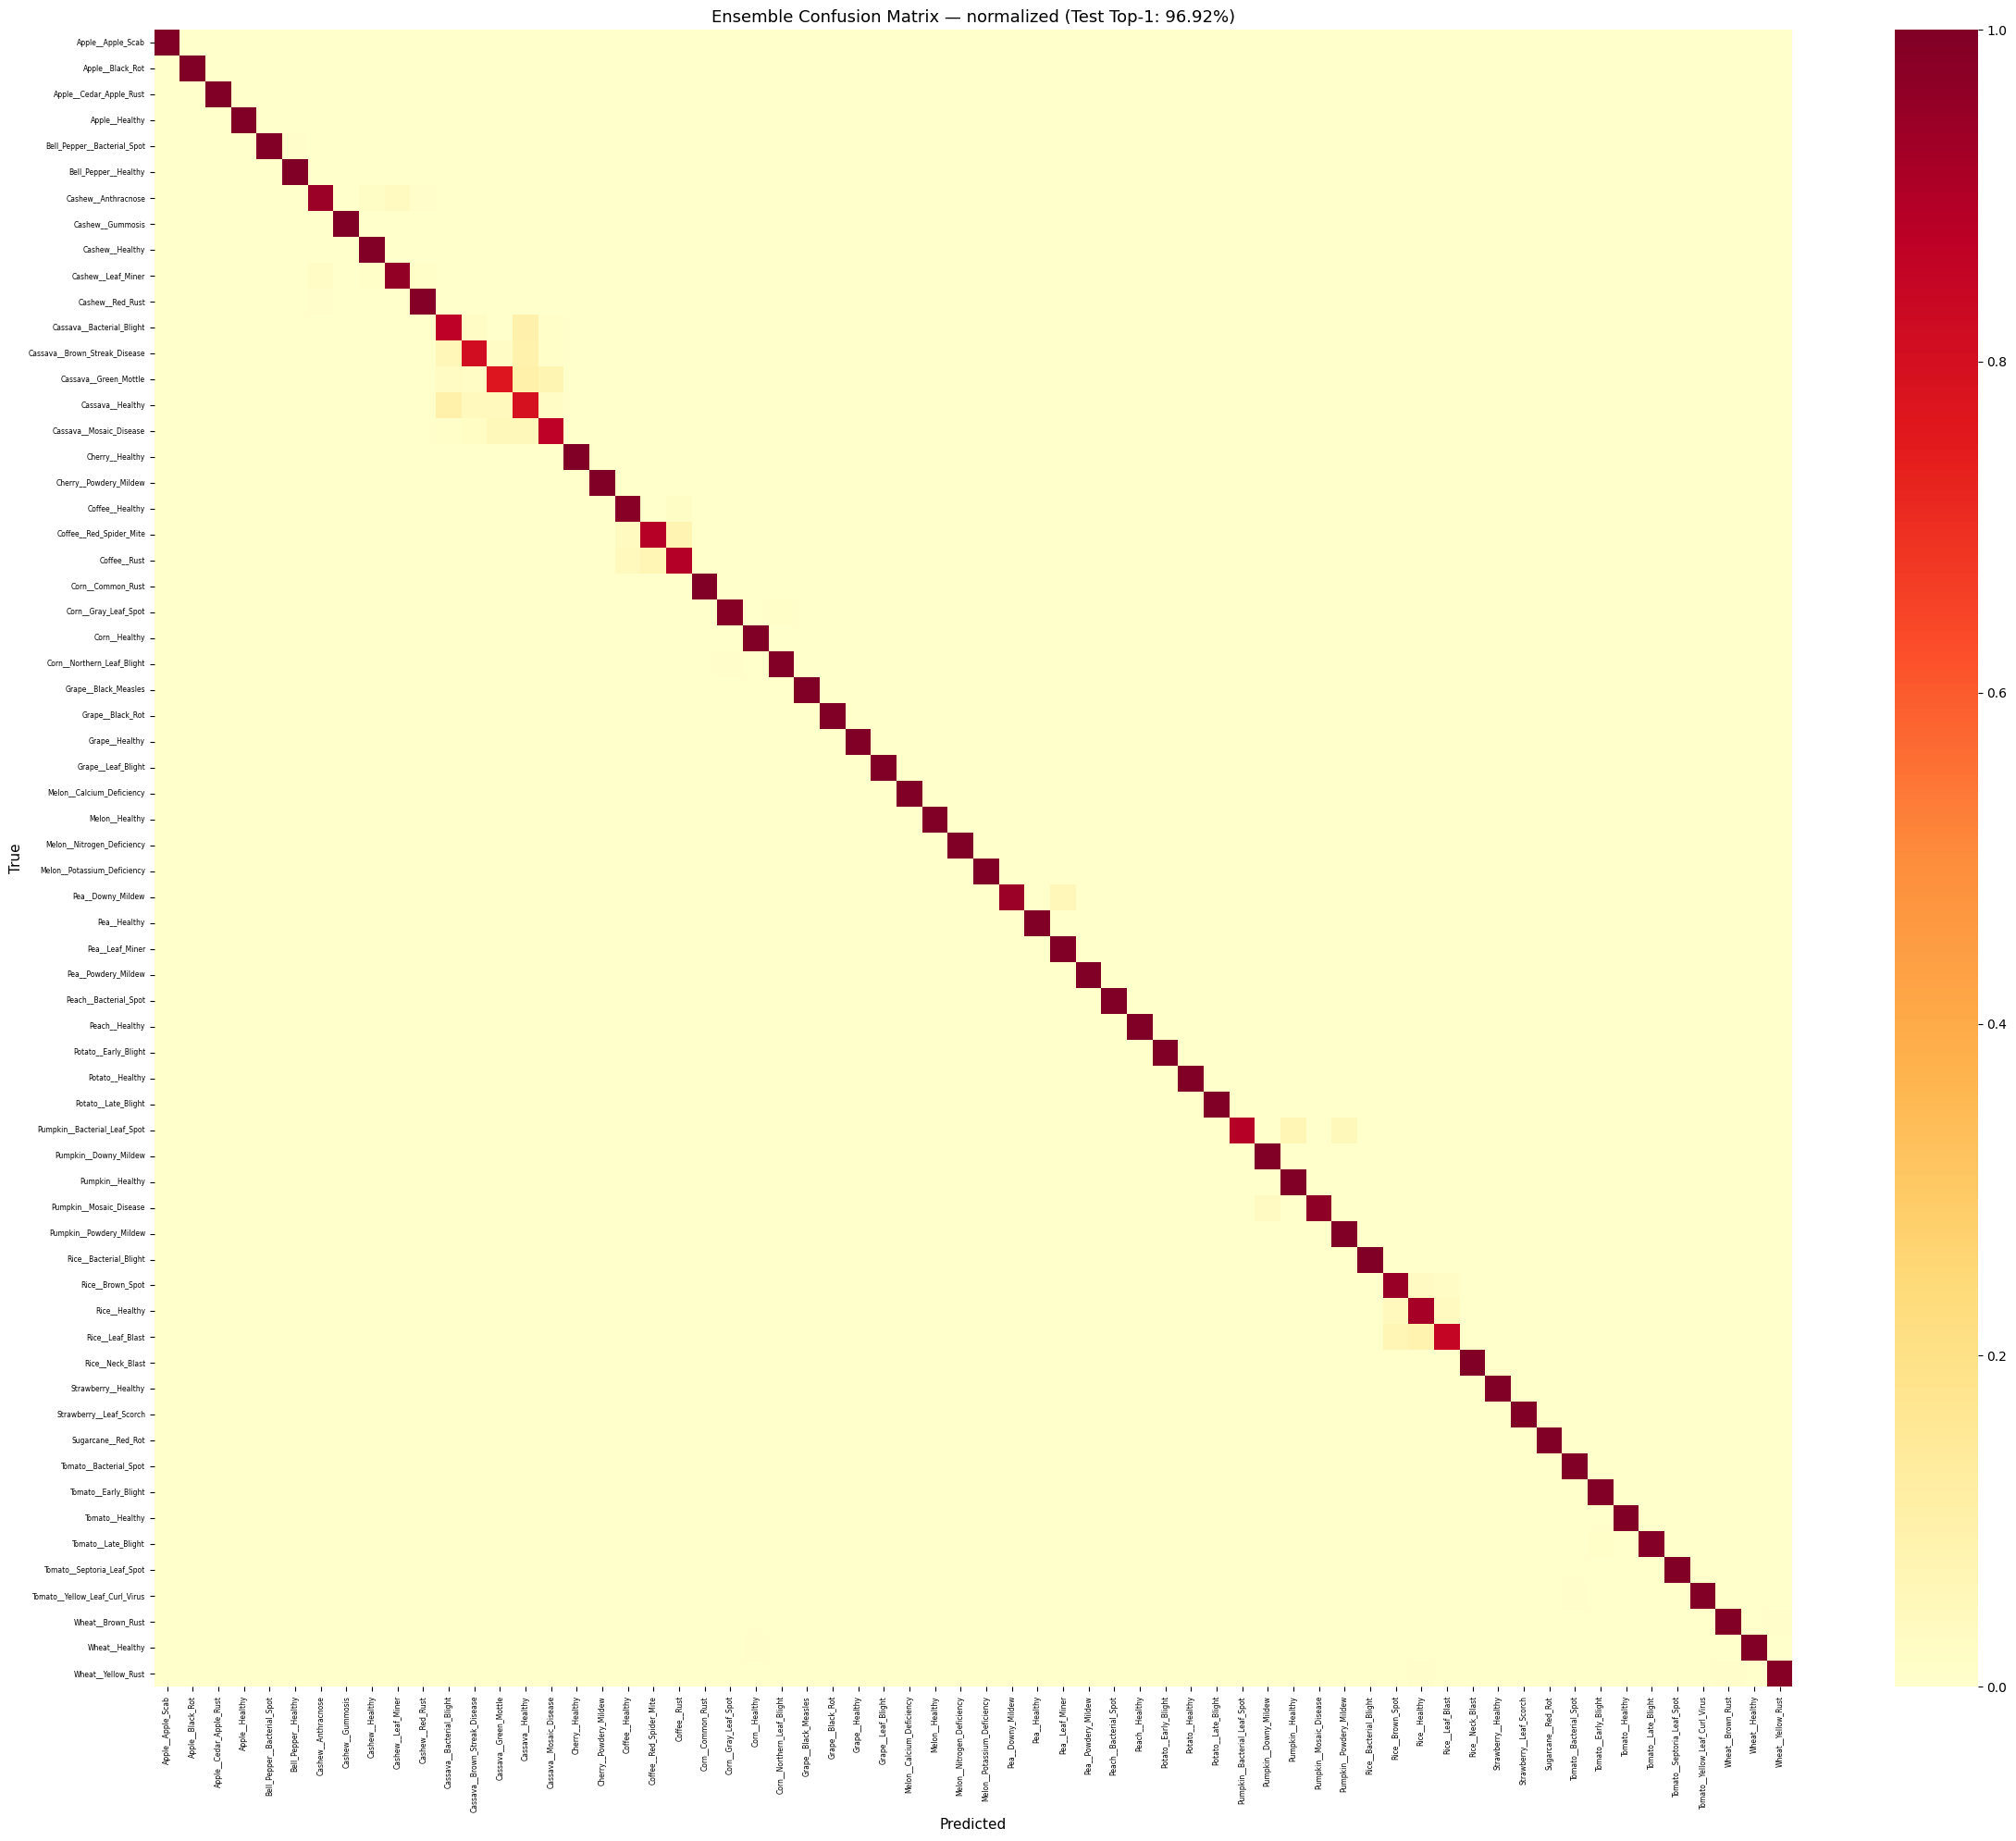


Top 15 most confused class pairs (true → predicted):
  Cassava__Mosaic_Disease                  → Cassava__Healthy                         (81 samples)
  Cassava__Mosaic_Disease                  → Cassava__Green_Mottle                    (78 samples)
  Cassava__Mosaic_Disease                  → Cassava__Brown_Streak_Disease            (43 samples)
  Cassava__Healthy                         → Cassava__Bacterial_Blight                (33 samples)
  Cassava__Green_Mottle                    → Cassava__Healthy                         (30 samples)
  Cashew__Anthracnose                      → Cashew__Leaf_Miner                       (26 samples)
  Cassava__Brown_Streak_Disease            → Cassava__Healthy                         (25 samples)
  Cassava__Green_Mottle                    → Cassava__Mosaic_Disease                  (22 samples)
  Cassava__Brown_Streak_Disease            → Cassava__Bacterial_Blight                (17 samples)
  Cassava__Mosaic_Disease                  → Cassava__B

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

cm      = np.load('/kaggle/working/runs/confusion_matrix.npy')
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(24, 20))
sns.heatmap(cm_norm, annot=False, cmap='YlOrRd',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0, vmin=0, vmax=1, ax=ax)
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('True', fontsize=11)
ax.set_title(f'Ensemble Confusion Matrix — normalized (Test Top-1: {top1_ens:.2f}%)', fontsize=13)
plt.xticks(rotation=90, fontsize=5.5)
plt.yticks(rotation=0,  fontsize=5.5)
plt.tight_layout()
plt.savefig('/kaggle/working/runs/confusion_matrix.png', dpi=150)
plt.show()

# Also print worst-confused pairs (useful for paper)
print("\nTop 15 most confused class pairs (true → predicted):")
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
flat = cm_no_diag.flatten()
top_idx = flat.argsort()[-15:][::-1]
for idx in top_idx:
    r, c = divmod(idx, len(class_names))
    print(f"  {class_names[r]:<40} → {class_names[c]:<40} ({cm[r,c]} samples)")

# Ablation Study

In [29]:
# ============================================================
# ABLATION STUDY
# ResNet | EfficientNet | DenseNet | Ensemble | Ensemble+FAISS
# ============================================================
import pandas as pd

# ── FAISS+Ensemble accuracy on test set ──────────────────────
# Uses: ensemble for high-confidence, FAISS k-NN override for low-confidence
CONFIDENCE_GATE = 0.80   # sync with your config

@torch.no_grad()
def ensemble_faiss_accuracy(backbones, predictor, test_samples, threshold=CONFIDENCE_GATE):
    ds     = CropDiseaseDataset(test_samples, transform=val_transform)
    loader = DataLoader(ds, batch_size=64, shuffle=False,
                        num_workers=num_workers, pin_memory=True)

    all_preds, all_true = [], []
    faiss_overrides = 0

    for imgs, labels in tqdm(loader, desc="Ensemble+FAISS"):
        imgs = imgs.to(device)

        # Ensemble soft vote
        probs_list = []
        for model in backbones.values():
            model.eval()
            with torch.amp.autocast('cuda'):
                logits = model(imgs)
            probs_list.append(torch.softmax(logits, dim=1))
        ens_probs = torch.stack(probs_list).mean(0)   # (B, 64)
        ens_conf, ens_pred = ens_probs.max(dim=1)

        # Extract features for FAISS
        parts = []
        for model in backbones.values():
            with torch.amp.autocast('cuda'):
                feat = model.extract_features(imgs)
            parts.append(feat)
        feats = F.normalize(torch.cat(parts, dim=1), p=2, dim=1).cpu().numpy()

        # Per-sample: use FAISS if ensemble confidence below gate
        batch_preds = ens_pred.cpu().numpy().copy()
        low_conf_mask = ens_conf.cpu().numpy() < threshold
        if low_conf_mask.any():
            low_feats = feats[low_conf_mask]
            _, I = predictor.index.search(low_feats.astype(np.float32), predictor.k)
            for j, neigh_idx in enumerate(I):
                knn_pred = np.bincount(predictor.labels[neigh_idx],
                                       minlength=n_classes).argmax()
                batch_preds[np.where(low_conf_mask)[0][j]] = knn_pred
            faiss_overrides += low_conf_mask.sum()

        all_preds.extend(batch_preds.tolist())
        all_true.extend(labels.numpy().tolist())

    all_preds  = np.array(all_preds)
    all_true   = np.array(all_true)
    top1       = (all_preds == all_true).mean() * 100
    print(f"  FAISS overrides applied: {faiss_overrides} / {len(all_true)} "
          f"({100*faiss_overrides/len(all_true):.1f}%)")
    return top1, all_preds


print("Running Ensemble+FAISS on test set...")
top1_faiss, faiss_preds = ensemble_faiss_accuracy(backbones, predictor, test_s_clean)

# ── Build ablation table ──────────────────────────────────────
rows = []
for name in backbone_names:
    r = backbone_results[name]
    rows.append({
        'Model':   name,
        'Top-1 %': round(r['top1'], 2),
        'Top-5 %': round(r['top5'], 2),
        'Delta vs Ensemble': round(r['top1'] - top1_ens, 2),
    })
rows.append({
    'Model':   'Ensemble (soft vote)',
    'Top-1 %': round(top1_ens, 2),
    'Top-5 %': round(top5_ens, 2),
    'Delta vs Ensemble': 0.0,
})
rows.append({
    'Model':   'Ensemble + FAISS',
    'Top-1 %': round(top1_faiss, 2),
    'Top-5 %': '—',
    'Delta vs Ensemble': round(top1_faiss - top1_ens, 2),
})

df = pd.DataFrame(rows)
print("\n" + "="*60)
print("  ABLATION TABLE — CropQuery Vision Module")
print("="*60)
print(df.to_string(index=False))

# Also save
df.to_csv('/kaggle/working/runs/ablation_table.csv', index=False)
print("\nSaved → ablation_table.csv")

# ── Confusion pairs for Ensemble+FAISS vs Ensemble ───────────
print("\nCassava F1 improvement with FAISS (target classes):")
from sklearn.metrics import f1_score
cassava_classes = [class_to_idx[c] for c in class_to_idx if 'Cassava' in c]
for idx in cassava_classes:
    mask = true_labels == idx
    if mask.sum() == 0: continue
    f1_ens   = f1_score(true_labels[mask], ensemble_preds[mask],
                        labels=[idx], average='micro', zero_division=0)
    f1_faiss = f1_score(true_labels[mask], faiss_preds[mask],
                        labels=[idx], average='micro', zero_division=0)
    cls_name = idx_to_class[idx]
    print(f"  {cls_name:<40} Ens: {f1_ens:.3f}  FAISS: {f1_faiss:.3f}  "
          f"Δ={f1_faiss-f1_ens:+.3f}")

Running Ensemble+FAISS on test set...


Ensemble+FAISS: 100%|██████████| 313/313 [08:51<00:00,  1.70s/it]


  FAISS overrides applied: 7390 / 19984 (37.0%)

  ABLATION TABLE — CropQuery Vision Module
               Model  Top-1 % Top-5 %  Delta vs Ensemble
            resnet50    96.52   99.92              -0.40
        efficientnet    87.69   95.49              -9.23
            densenet    96.04   99.87              -0.88
Ensemble (soft vote)    96.92   99.94               0.00
    Ensemble + FAISS    97.83       —               0.91

Saved → ablation_table.csv

Cassava F1 improvement with FAISS (target classes):
  Cassava__Bacterial_Blight                Ens: 0.930  FAISS: 0.869  Δ=-0.061
  Cassava__Brown_Streak_Disease            Ens: 0.896  FAISS: 0.904  Δ=+0.009
  Cassava__Green_Mottle                    Ens: 0.872  FAISS: 0.852  Δ=-0.019
  Cassava__Healthy                         Ens: 0.883  FAISS: 0.839  Δ=-0.044
  Cassava__Mosaic_Disease                  Ens: 0.929  FAISS: 0.984  Δ=+0.054


In [30]:
# ============================================================
# FAISS THRESHOLD SWEEP — find optimal confidence gate
# ============================================================
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.99]

# Pre-compute ensemble probs and features for entire test set (one pass)
print("Pre-computing ensemble probs and features for test set...")

@torch.no_grad()
def precompute_test(backbones, test_samples):
    ds     = CropDiseaseDataset(test_samples, transform=val_transform)
    loader = DataLoader(ds, batch_size=64, shuffle=False,
                        num_workers=num_workers, pin_memory=True)
    all_probs, all_feats, all_true = [], [], []
    for imgs, labels in tqdm(loader, desc="Pre-computing"):
        imgs = imgs.to(device)
        probs_list = []
        parts = []
        for model in backbones.values():
            model.eval()
            with torch.amp.autocast('cuda'):
                logits = model(imgs)
                feat   = model.extract_features(imgs)
            probs_list.append(torch.softmax(logits, dim=1))
            parts.append(feat)
        ens_probs = torch.stack(probs_list).mean(0).cpu()
        feats = F.normalize(torch.cat(parts, dim=1), p=2, dim=1).cpu()
        all_probs.append(ens_probs)
        all_feats.append(feats)
        all_true.append(labels)
    return torch.cat(all_probs), torch.cat(all_feats).numpy(), torch.cat(all_true).numpy()

ens_probs_all, feats_all, true_all = precompute_test(backbones, test_s_clean)
ens_conf_all, ens_pred_all = ens_probs_all.max(dim=1)
ens_conf_all = ens_conf_all.numpy()
ens_pred_all = ens_pred_all.numpy()

print(f"\nConfidence distribution:")
for t in thresholds:
    pct = (ens_conf_all < t).mean() * 100
    print(f"  < {t:.2f} : {pct:.1f}% of samples would trigger FAISS")

print("\nThreshold sweep:")
print(f"  {'Threshold':>10}  {'FAISS %':>8}  {'Top-1 %':>8}")
print("  " + "-"*32)

best_top1, best_thresh = 0, 0
for thresh in thresholds:
    low_mask = ens_conf_all < thresh
    preds = ens_pred_all.copy()
    if low_mask.any():
        low_feats = feats_all[low_mask].astype(np.float32)
        _, I = predictor.index.search(low_feats, predictor.k)
        for j, neigh_idx in enumerate(I):
            knn_pred = np.bincount(predictor.labels[neigh_idx],
                                   minlength=n_classes).argmax()
            preds[np.where(low_mask)[0][j]] = knn_pred
    top1 = (preds == true_all).mean() * 100
    faiss_pct = low_mask.mean() * 100
    marker = " ←" if top1 > best_top1 else ""
    print(f"  {thresh:>10.2f}  {faiss_pct:>7.1f}%  {top1:>7.2f}%{marker}")
    if top1 > best_top1:
        best_top1, best_thresh = top1, thresh

print(f"\n  Optimal threshold: {best_thresh:.2f}  →  Top-1: {best_top1:.2f}%")
print(f"  (Baseline ensemble no FAISS: {top1_ens:.2f}%)")

Pre-computing ensemble probs and features for test set...


Pre-computing: 100%|██████████| 313/313 [03:03<00:00,  1.71it/s]



Confidence distribution:
  < 0.50 : 4.3% of samples would trigger FAISS
  < 0.60 : 13.4% of samples would trigger FAISS
  < 0.70 : 20.5% of samples would trigger FAISS
  < 0.80 : 37.0% of samples would trigger FAISS
  < 0.85 : 81.3% of samples would trigger FAISS
  < 0.90 : 99.6% of samples would trigger FAISS
  < 0.95 : 100.0% of samples would trigger FAISS
  < 0.99 : 100.0% of samples would trigger FAISS

Threshold sweep:
   Threshold   FAISS %   Top-1 %
  --------------------------------
        0.50      4.3%    97.63% ←
        0.60     13.4%    97.78% ←
        0.70     20.5%    97.82% ←
        0.80     37.0%    97.83% ←
        0.85     81.3%    97.83%
        0.90     99.6%    97.83%
        0.95    100.0%    97.83%
        0.99    100.0%    97.83%

  Optimal threshold: 0.80  →  Top-1: 97.83%
  (Baseline ensemble no FAISS: 96.92%)
